# MET 421 Final Project Plot and Analysis

**Name:** Gabriel Salinas  
**Assignment:** Final Case Study Python Plots  
**Event:** 24 May 2011 Tornado Outbreak, focused on the El Reno-Piedmont, Oklahoma EF5 tornado

I chose this event because the El Reno-Piedmont tornado was one of the most violent tornadoes of the 24 May 2011 outbreak. The tornado was rated EF5, produced extreme damage, and occurred in an environment with strong instability, low-level moisture, and vertical wind shear. These plots focus on the synoptic and near-storm environment around 18Z on 24 May 2011, shortly before the main tornadic activity in central Oklahoma.

In [2]:
# Import packages needed for all final project plots

import matplotlib.pyplot as plt
import xarray as xr
import metpy.calc as mpcalc
from metpy.units import units
import numpy as np

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from datetime import datetime
from siphon.simplewebservice.wyoming import WyomingUpperAir
from metpy.plots import SkewT, Hodograph
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


## Figure 1: 500 hPa Geopotential Height and Geostrophic Wind

This plot shows 500 hPa geopotential height contoured in meters with calculated geostrophic wind barbs. The 500 hPa level is useful in synoptic analysis because it shows the mid-level height pattern, including troughs, ridges, and stronger flow aloft. For this tornado outbreak, the 500 hPa pattern helps show the larger-scale upper-level support and deep-layer flow that favored organized severe thunderstorms across Oklahoma.

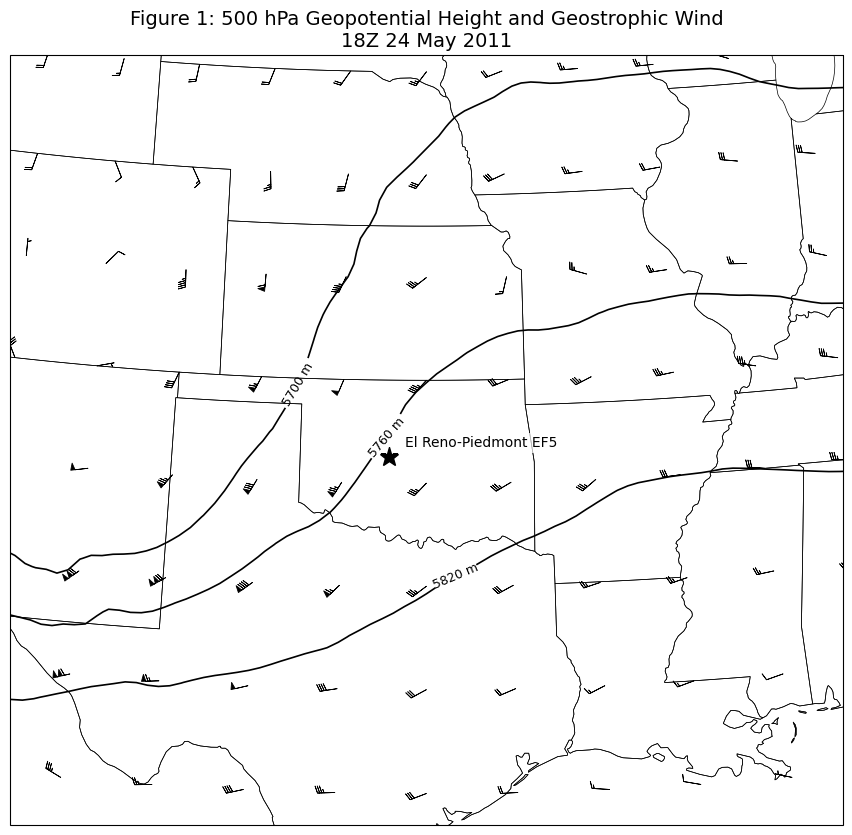

In [11]:
# Figure 1: 500 hPa geopotential height and geostrophic wind

# Open the ERA5 NetCDF file containing 500 hPa geopotential
ds = xr.open_dataset('20110524_500hpa.nc')

# Identify coordinate names in the file
lon_name = 'longitude' if 'longitude' in ds.coords else 'lon'
lat_name = 'latitude' if 'latitude' in ds.coords else 'lat'

# Convert longitudes
if ds[lon_name].max() > 180:
    ds = ds.assign_coords({lon_name: (((ds[lon_name] + 180) % 360) - 180)})
    ds = ds.sortby(lon_name)

# Select geopotential from the dataset
z = ds['z']

# Select the only/first time in the file
if 'valid_time' in z.dims:
    z = z.isel(valid_time=0)
elif 'time' in z.dims:
    z = z.isel(time=0)

# Select the 500 hPa pressure level if a pressure-level dimension exists
if 'pressure_level' in z.dims:
    z = z.sel(pressure_level=500)
elif 'level' in z.dims:
    z = z.sel(level=500)
elif 'isobaricInhPa' in z.dims:
    z = z.sel(isobaricInhPa=500)

# Remove any leftover single-length dimensions
z = z.squeeze(drop=True)

# Convert ERA5 geopotential from m^2/s^2 to geopotential height in meters
height = z / 9.80665

# Sort latitude from south to north for cleaner plotting/calculations
height = height.sortby(lat_name)

# Extract latitude and longitude arrays
lats = height[lat_name].values
lons = height[lon_name].values
lons_2d, lats_2d = np.meshgrid(lons, lats)

# Calculate grid spacing between latitude/longitude points
# This spacing is needed for the geostrophic wind calculation
dx, dy = mpcalc.lat_lon_grid_deltas(lons, lats)

# Add units to the height field before calculating geostrophic wind
height_with_units = height.values * units.meter

# Calculate geostrophic wind from the 500 hPa height gradient
u_geo, v_geo = mpcalc.geostrophic_wind(
    height_with_units,
    dx=dx,
    dy=dy,
    latitude=lats_2d * units.degrees,
    x_dim=-1,
    y_dim=-2
)

# Convert geostrophic wind from m/s to knots
u_geo_kt = u_geo.to('knots')
v_geo_kt = v_geo.to('knots')

# Create map projection
mapcrs = ccrs.LambertConformal(central_longitude=-97, central_latitude=35)
datacrs = ccrs.PlateCarree()

# Create figure and map axes
fig = plt.figure(figsize=(14, 10))
ax = plt.axes(projection=mapcrs)

# Set map extent around the central/southern Plains
ax.set_extent([-106, -88, 28, 43], crs=datacrs)

# Add map features
ax.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=0.5)
ax.add_feature(cfeature.BORDERS.with_scale('50m'), linewidth=0.5)
ax.add_feature(cfeature.STATES.with_scale('50m'), linewidth=0.5)

# Plot 500 hPa isohypses every 60 meters
cs5700 = ax.contour(lons, lats, height.values, levels=[5700], colors='black', linewidths=1.2, transform=datacrs)
cs5760 = ax.contour(lons, lats, height.values, levels=[5760], colors='black', linewidths=1.2, transform=datacrs)
cs5820 = ax.contour(lons, lats, height.values, levels=[5820], colors='black', linewidths=1.2, transform=datacrs)

# Label each isohypse manually
ax.clabel(cs5700, fmt={5700: '5700 m'}, inline=True, inline_spacing=5, fontsize=9, manual=[(-90.0, 42.2)])
ax.clabel(cs5760, fmt={5760: '5760 m'}, inline=True, inline_spacing=5, fontsize=9, manual=[(-101.0, 34.8)])
ax.clabel(cs5820, fmt={5820: '5820 m'}, inline=True, inline_spacing=5, fontsize=9, manual=[(-98.5, 30.8)])

# Skip grid points so wind barbs are readable
skip = (slice(None, None, 8), slice(None, None, 8))

# Plot geostrophic wind barbs
ax.barbs(
    lons_2d[skip],
    lats_2d[skip],
    u_geo_kt.magnitude[skip],
    v_geo_kt.magnitude[skip],
    length=5,
    linewidth=0.6,
    transform=datacrs
)

# Mark the approximate El Reno-Piedmont tornado area
ax.plot(-97.9, 35.5, marker='*', markersize=14, color='black', transform=datacrs)
ax.text(
    -97.5, 35.7,
    'El Reno-Piedmont EF5',
    fontsize=10,
    transform=datacrs,
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=2)
)

# Add title, save, and display
plt.title(
    'Figure 1: 500 hPa Geopotential Height and Geostrophic Wind\n'
    '18Z 24 May 2011',
    fontsize=14
)
plt.savefig('figure1_500hpa_height_geostrophic_wind_18Z.png', dpi=300, bbox_inches='tight')
plt.show()


## Figure 2: 850 hPa Wind Speed and Specific Humidity

This plot shows 850 hPa wind speed shaded in knots, specific humidity contoured in green, and 850 hPa wind barbs. The 850 hPa level is useful because it shows low-level flow and moisture transport, which are important for identifying the low-level jet and warm/moist inflow into the severe weather area. In this case, the plot shows stronger low-level flow and relatively moist air near Oklahoma, helping support the unstable warm sector ahead of tornadic supercells.

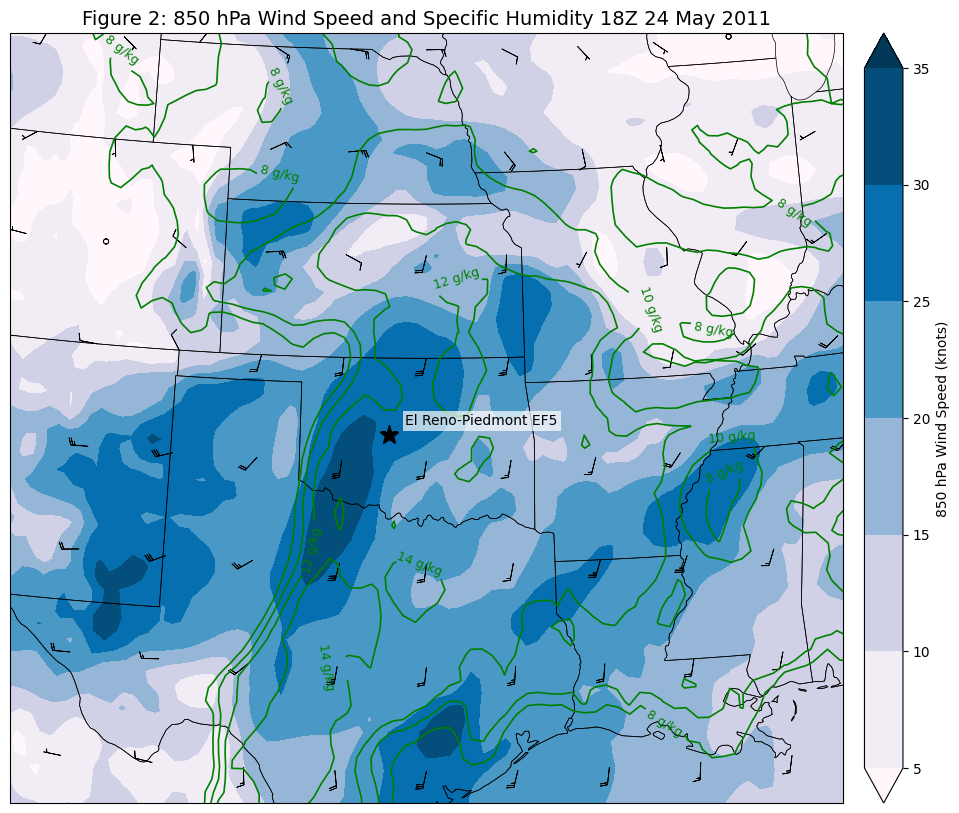

In [7]:
# Figure 2: 850 hPa wind speed and specific humidity

# Open the ERA5 NetCDF file containing 850 hPa u-wind, v-wind, and specific humidity
ds850 = xr.open_dataset('20110524_18Z_850hpa_wind_moisture.nc')

# Select variables
u850 = ds850['u']
v850 = ds850['v']
q850 = ds850['q']

# Select the only/first time in the file
if 'valid_time' in u850.dims:
    u850 = u850.isel(valid_time=0)
    v850 = v850.isel(valid_time=0)
    q850 = q850.isel(valid_time=0)
elif 'time' in u850.dims:
    u850 = u850.isel(time=0)
    v850 = v850.isel(time=0)
    q850 = q850.isel(time=0)

# Select the 850 hPa pressure level
if 'pressure_level' in u850.dims:
    u850 = u850.sel(pressure_level=850)
    v850 = v850.sel(pressure_level=850)
    q850 = q850.sel(pressure_level=850)
elif 'level' in u850.dims:
    u850 = u850.sel(level=850)
    v850 = v850.sel(level=850)
    q850 = q850.sel(level=850)

# Remove any leftover single-length dimensions
u850 = u850.squeeze(drop=True)
v850 = v850.squeeze(drop=True)
q850 = q850.squeeze(drop=True)

# Identify coordinate names
lat_name = 'latitude' if 'latitude' in u850.coords else 'lat'
lon_name = 'longitude' if 'longitude' in u850.coords else 'lon'

# Convert longitudes
if u850[lon_name].max() > 180:
    u850 = u850.assign_coords({lon_name: (((u850[lon_name] + 180) % 360) - 180)}).sortby(lon_name)
    v850 = v850.assign_coords({lon_name: (((v850[lon_name] + 180) % 360) - 180)}).sortby(lon_name)
    q850 = q850.assign_coords({lon_name: (((q850[lon_name] + 180) % 360) - 180)}).sortby(lon_name)

# Sort latitude from south to north
u850 = u850.sortby(lat_name)
v850 = v850.sortby(lat_name)
q850 = q850.sortby(lat_name)

# Extract coordinates and make 2D arrays for wind barbs
lats850 = u850[lat_name].values
lons850 = u850[lon_name].values
lons850_2d, lats850_2d = np.meshgrid(lons850, lats850)

# Calculate 850 hPa wind speed in knots
wind_speed_850 = mpcalc.wind_speed(u850.values * units('m/s'), v850.values * units('m/s')).to('knots')

# Convert specific humidity from kg/kg to g/kg
q850_gkg = q850.values * 1000

# Create map projection
mapcrs = ccrs.LambertConformal(central_longitude=-97, central_latitude=35)
datacrs = ccrs.PlateCarree()

# Create figure and map axes
fig = plt.figure(figsize=(14, 10))
ax = plt.axes(projection=mapcrs)
ax.set_extent([-106, -88, 28, 43], crs=datacrs)

# Add map features
ax.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=0.5)
ax.add_feature(cfeature.BORDERS.with_scale('50m'), linewidth=0.5)
ax.add_feature(cfeature.STATES.with_scale('50m'), linewidth=0.5)

# Plot 850 hPa wind speed as filled contours
wind_levels = np.arange(5, 36, 5)
cmap='YlGnBu'
wind_fill = ax.contourf(
    lons850,
    lats850,
    wind_speed_850.magnitude,
    levels=wind_levels,
    cmap='PuBu',
    extend='both',
    transform=datacrs
)

# Add colorbar for wind speed
cbar = plt.colorbar(wind_fill, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label('850 hPa Wind Speed (knots)')

# Plot specific humidity contours in g/kg
q_levels = np.arange(8, 18, 2)
q_contours = ax.contour(
    lons850,
    lats850,
    q850_gkg,
    levels=q_levels,
    colors='green',
    linewidths=1.2,
    transform=datacrs
)
ax.clabel(q_contours, inline=True, fontsize=9, fmt='%d g/kg')

# Plot readable wind barbs
skip = (slice(None, None, 8), slice(None, None, 8))
ax.barbs(
    lons850_2d[skip],
    lats850_2d[skip],
    u850.values[skip] * 1.94384,
    v850.values[skip] * 1.94384,
    length=5,
    linewidth=0.6,
    transform=datacrs
)

# Mark the approximate El Reno-Piedmont tornado area
ax.plot(-97.9, 35.5, marker='*', markersize=14, color='black', transform=datacrs)
ax.text(
    -97.5, 35.7,
    'El Reno-Piedmont EF5',
    fontsize=10,
    transform=datacrs,
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=2)
)

# Add title, save, and display
plt.title('Figure 2: 850 hPa Wind Speed and Specific Humidity 18Z 24 May 2011', fontsize=14)
plt.savefig('figure2_850hpa_wind_specific_humidity_18Z.png', dpi=300, bbox_inches='tight')
plt.show()


## Figure 3: Surface Dewpoint and Mean Sea-Level Pressure

This plot shows 2-meter dewpoint shaded in degrees Fahrenheit with mean sea-level pressure contoured in hPa. Surface dewpoint is useful for locating the warm, moist sector and identifying sharp moisture gradients such as a dryline. Mean sea-level pressure helps show the broader surface pressure pattern and areas of convergence. For this event, high dewpoints across Oklahoma and north Texas indicate rich low-level moisture feeding the severe thunderstorm environment.

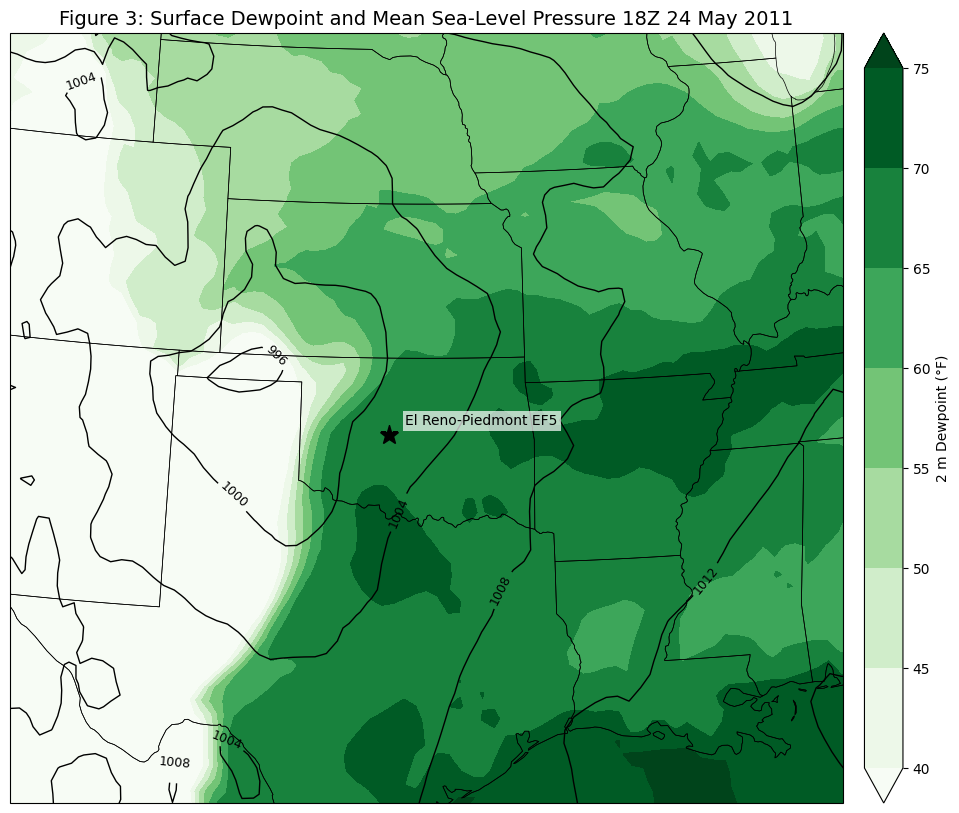

In [9]:
# Figure 3: Surface dewpoint and mean sea-level pressure

# Open the ERA5 NetCDF file containing 2 m dewpoint and mean sea-level pressure
ds_sfc = xr.open_dataset('20110524_18Z_surface_dewpoint_mslp.nc')

# Select variables
d2m = ds_sfc['d2m']   # 2 meter dewpoint temperature
mslp = ds_sfc['msl']  # mean sea-level pressure

# Select the only/first time in the file
if 'valid_time' in d2m.dims:
    d2m = d2m.isel(valid_time=0)
    mslp = mslp.isel(valid_time=0)
elif 'time' in d2m.dims:
    d2m = d2m.isel(time=0)
    mslp = mslp.isel(time=0)

# Remove any leftover single-length dimensions
d2m = d2m.squeeze(drop=True)
mslp = mslp.squeeze(drop=True)

# Identify coordinate names
lat_name = 'latitude' if 'latitude' in d2m.coords else 'lat'
lon_name = 'longitude' if 'longitude' in d2m.coords else 'lon'

# Convert longitudes
if d2m[lon_name].max() > 180:
    d2m = d2m.assign_coords({lon_name: (((d2m[lon_name] + 180) % 360) - 180)}).sortby(lon_name)
    mslp = mslp.assign_coords({lon_name: (((mslp[lon_name] + 180) % 360) - 180)}).sortby(lon_name)

# Sort latitude from south to north
d2m = d2m.sortby(lat_name)
mslp = mslp.sortby(lat_name)

# Extract coordinate arrays
lats_sfc = d2m[lat_name].values
lons_sfc = d2m[lon_name].values

# Convert dewpoint from Kelvin to degrees Fahrenheit
dewpoint_f = ((d2m.values - 273.15) * 9/5) + 32

# Convert mean sea-level pressure from Pa to hPa
mslp_hpa = mslp.values / 100.0

# Create map projection
mapcrs = ccrs.LambertConformal(central_longitude=-97, central_latitude=35)
datacrs = ccrs.PlateCarree()

# Create figure and map axes
fig = plt.figure(figsize=(14, 10))
ax = plt.axes(projection=mapcrs)
ax.set_extent([-106, -88, 28, 43], crs=datacrs)

# Add map features
ax.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=0.5)
ax.add_feature(cfeature.BORDERS.with_scale('50m'), linewidth=0.5)
ax.add_feature(cfeature.STATES.with_scale('50m'), linewidth=0.5)

# Plot surface dewpoint as filled contours
dew_levels = np.arange(40, 76, 5)
dew_fill = ax.contourf(
    lons_sfc,
    lats_sfc,
    dewpoint_f,
    levels=dew_levels,
    cmap='Greens',
    extend='both',
    transform=datacrs
)

# Add colorbar for dewpoint
cbar = plt.colorbar(dew_fill, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label('2 m Dewpoint (°F)')

# Plot mean sea-level pressure contours every 4 hPa
mslp_levels = np.arange(
    int(np.nanmin(mslp_hpa) // 4 * 4),
    int(np.nanmax(mslp_hpa) // 4 * 4 + 4),
    4
)
mslp_contours = ax.contour(
    lons_sfc,
    lats_sfc,
    mslp_hpa,
    levels=mslp_levels,
    colors='black',
    linewidths=1.0,
    transform=datacrs
)
ax.clabel(mslp_contours, inline=True, fontsize=9, fmt='%d')

# Mark the approximate El Reno-Piedmont tornado area
ax.plot(-97.9, 35.5, marker='*', markersize=14, color='black', transform=datacrs)
ax.text(
    -97.5, 35.7,
    'El Reno-Piedmont EF5',
    fontsize=10,
    transform=datacrs,
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=2)
)

# Add title, save, and display
plt.title('Figure 3: Surface Dewpoint and Mean Sea-Level Pressure 18Z 24 May 2011', fontsize=14)
plt.savefig('figure3_surface_dewpoint_mslp_18Z.png', dpi=300, bbox_inches='tight')
plt.show()


## Figure 4: Norman, Oklahoma Proximity Sounding

This plot shows an 18Z proximity sounding from Norman, Oklahoma, using observed upper-air data. The Skew-T includes temperature, dewpoint, wind barbs, a surface parcel path, shaded CAPE/CIN, and an inset hodograph. This is useful because it summarizes the thermodynamic and kinematic environment near the tornado area.

The sounding shows strong surface-based instability, with SBCAPE near 3000 J/kg, meaning the atmosphere had substantial buoyant energy available for thunderstorm updrafts. SBCIN was about -71 J/kg, showing some inhibition still existed, but not enough to prevent severe convection once lift overcame the cap. The LCL was around 901 hPa, indicating relatively low cloud bases. The 0-6 km bulk shear was about 46 kt, which is supportive of organized supercells. Overall, this sounding shows a moist, unstable, and strongly sheared environment favorable for tornadic supercells during the outbreak.

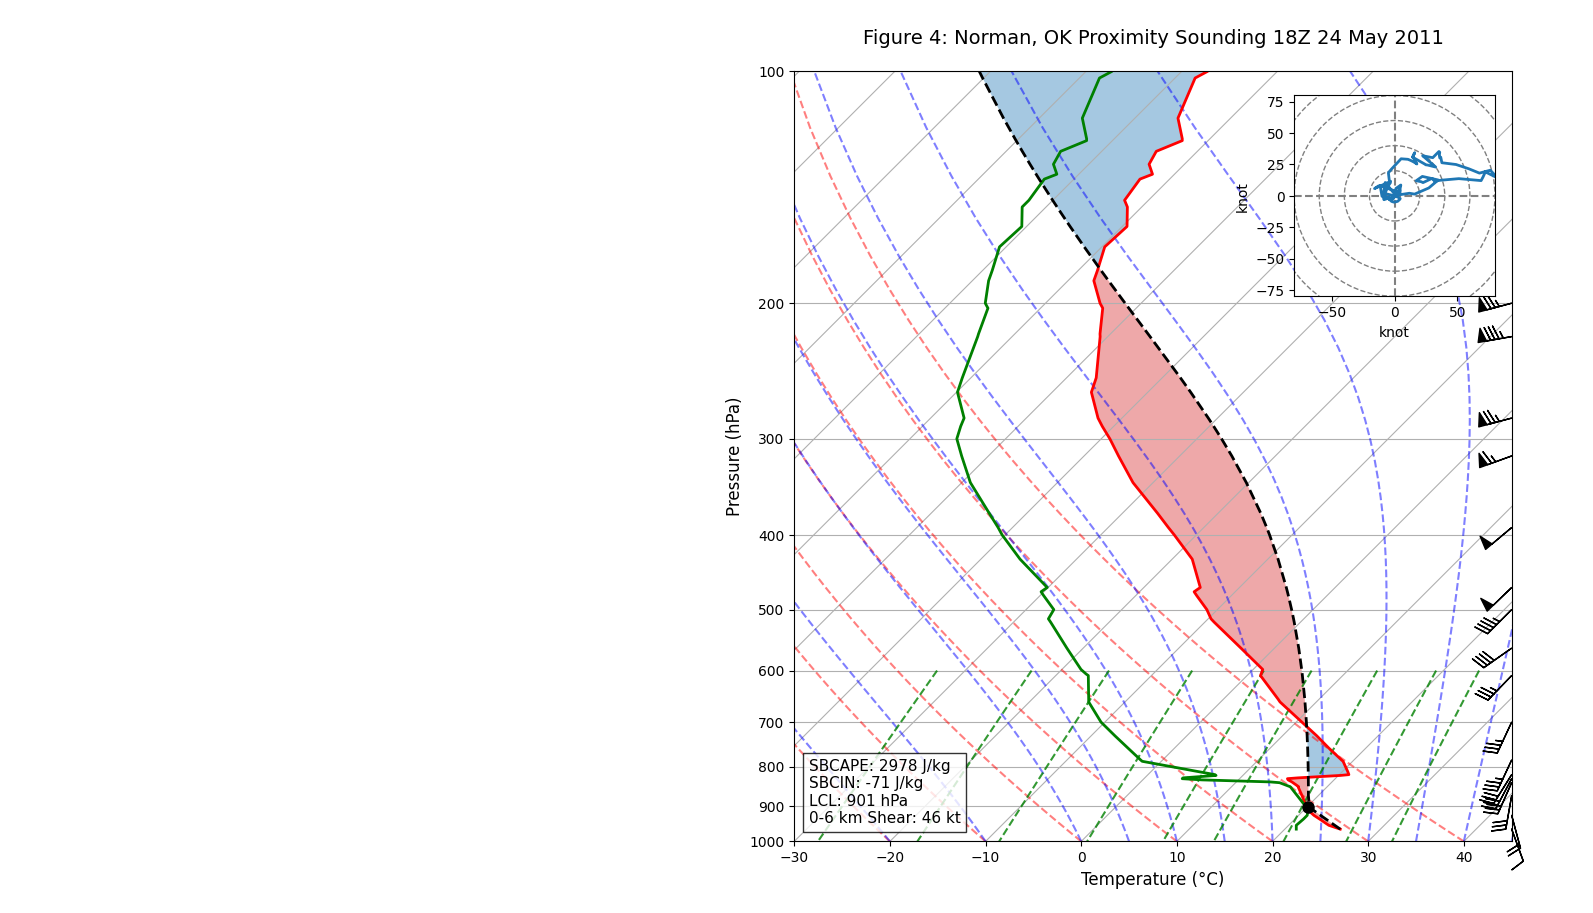

In [8]:
# Figure 4: Norman, Oklahoma proximity sounding

# Request the 18Z 24 May 2011 sounding from Norman, Oklahoma
date = datetime(2011, 5, 24, 18)
station = 'OUN'
df = WyomingUpperAir.request_data(date, station)

# Drop rows with missing pressure, temperature, dewpoint, wind direction, or wind speed
df = df.dropna(subset=['pressure', 'temperature', 'dewpoint', 'direction', 'speed'])

# Create pressure, temperature, and dewpoint variables with units
p = df['pressure'].values * units.hPa
T = df['temperature'].values * units.degC
Td = df['dewpoint'].values * units.degC

# Create wind speed and wind direction variables with units
wind_speed = df['speed'].values * units.knots
wind_dir = df['direction'].values * units.degrees

# Convert wind speed/direction into u and v wind components
u, v = mpcalc.wind_components(wind_speed, wind_dir)

# Add height with units for bulk shear calculation
height = df['height'].values * units.meter

# Calculate surface-based CAPE and CIN
sbcape, sbcin = mpcalc.surface_based_cape_cin(p, T, Td)

# Calculate the lifting condensation level (LCL)
lcl_pressure, lcl_temperature = mpcalc.lcl(p[0], T[0], Td[0])

# Calculate a surface-based parcel profile
parcel_prof = mpcalc.parcel_profile(p, T[0], Td[0]).to('degC')

# Calculate 0-6 km bulk shear
u_shear, v_shear = mpcalc.bulk_shear(
    p,
    u,
    v,
    height=height,
    depth=6000 * units.meter
)
bulk_shear_06 = mpcalc.wind_speed(u_shear, v_shear).to('knots')

# Create a text box with key sounding values
text = (
    f"SBCAPE: {sbcape.magnitude:.0f} J/kg\n"
    f"SBCIN: {sbcin.magnitude:.0f} J/kg\n"
    f"LCL: {lcl_pressure.magnitude:.0f} hPa\n"
    f"0-6 km Shear: {bulk_shear_06.magnitude:.0f} kt"
)

# Create figure and Skew-T plot
fig = plt.figure(figsize=(12, 10))
skew = SkewT(fig, rotation=45)

# Plot temperature and dewpoint profiles
skew.plot(p, T, color='red', linewidth=2, label='Temperature')
skew.plot(p, Td, color='green', linewidth=2, label='Dewpoint')

# Plot wind barbs along the right side of the Skew-T
barb_mask = p >= 200 * units.hPa
skew.plot_barbs(
    p[barb_mask][::3],
    u[barb_mask][::3],
    v[barb_mask][::3],
    xloc=1.0
)

# Plot surface parcel profile and mark the LCL
skew.plot(p, parcel_prof, color='black', linewidth=2, linestyle='--', label='Surface Parcel')
skew.plot(lcl_pressure, lcl_temperature, marker='o', color='black', markersize=8)

# Shade CAPE and CIN
skew.shade_cape(p, T, parcel_prof)
skew.shade_cin(p, T, parcel_prof)

# Set Skew-T limits
skew.ax.set_ylim(1000, 100)
skew.ax.set_xlim(-30, 45)

# Add standard Skew-T background lines
skew.plot_dry_adiabats()
skew.plot_moist_adiabats()
skew.plot_mixing_lines()

# Add hodograph inset
ax_hod = inset_axes(skew.ax, '28%', '28%', loc='upper right', borderpad=1.2)
h = Hodograph(ax_hod, component_range=80)
h.add_grid(increment=20)
h.plot(u.to('knots'), v.to('knots'), linewidth=2)

# Add text box with key sounding values
skew.ax.text(
    0.02,
    0.02,
    text,
    transform=skew.ax.transAxes,
    fontsize=11,
    verticalalignment='bottom',
    bbox=dict(facecolor='white', edgecolor='black', alpha=0.8)
)

# Label axes
skew.ax.set_xlabel('Temperature (°C)', fontsize=12)
skew.ax.set_ylabel('Pressure (hPa)', fontsize=12)

# Add title, save, and display
skew.ax.set_title('Figure 4: Norman, OK Proximity Sounding 18Z 24 May 2011', fontsize=14, pad=20)
plt.savefig('figure4_norman_proximity_sounding_18Z.png', dpi=300, bbox_inches='tight')
plt.show()